In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("~/Desktop/flight/airline.csv")
df.head()

,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,ORIGIN,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY_NEW,DEP_DEL15,DISTANCE
0,1/1/2025 12:00:00 AM,AA,10140,1014005,30140,ABQ,11298,1129806,30194,DFW,500,452.0,0.0,0.0,569.0
1,1/1/2025 12:00:00 AM,AA,10140,1014005,30140,ABQ,11298,1129806,30194,DFW,555,552.0,0.0,0.0,569.0
2,1/1/2025 12:00:00 AM,AA,10140,1014005,30140,ABQ,11298,1129806,30194,DFW,820,815.0,0.0,0.0,569.0
3,1/1/2025 12:00:00 AM,AA,10140,1014005,30140,ABQ,11298,1129806,30194,DFW,1032,1029.0,0.0,0.0,569.0
4,1/1/2025 12:00:00 AM,AA,10140,1014005,30140,ABQ,11298,1129806,30194,DFW,1700,1707.0,7.0,0.0,569.0


In [9]:
airports = ["ORD", "MSN"]
selected_flights = df[df["ORIGIN"].isin(airports)].copy()

print(selected_flights["ORIGIN"].value_counts())

ORIGIN
ORD    21643
MSN      961
Name: count, dtype: int64


In [11]:
# delayed flights at each airport
ord_delayed = (selected_flights[
    selected_flights["ORIGIN"] == "ORD"
]["DEP_DEL15"] == 1).sum()

msn_delayed = (selected_flights[
    selected_flights["ORIGIN"] == "MSN"
]["DEP_DEL15"] == 1).sum()

print(ord_delayed, msn_delayed)

4191 150


In [12]:
ord = selected_flights[selected_flights["ORIGIN"] == "ORD"]
msn = selected_flights[selected_flights["ORIGIN"] == "MSN"]

ord_total = ord["DEP_DEL15"].count()
msn_total = msn["DEP_DEL15"].count()

# Calculating delay rates
ord_rate = ord_delayed / ord_total * 100
msn_rate = msn_delayed / msn_total * 100

print(round(ord_rate, 2), round(msn_rate, 2))

19.69 15.99


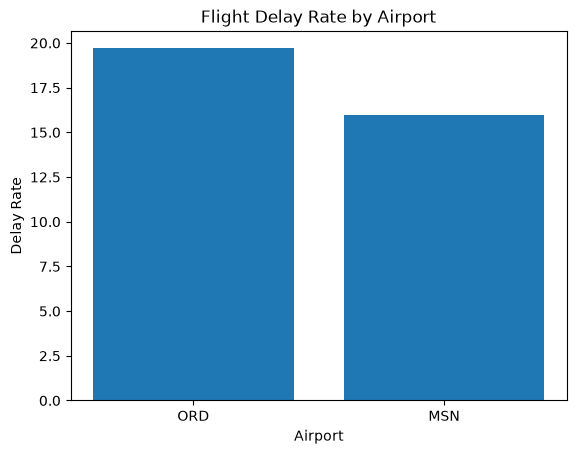

In [14]:
airports = ["ORD", "MSN"]
delay_rates = [ord_rate, msn_rate]

plt.bar(airports, delay_rates)

plt.title("Flight Delay Rate by Airport")
plt.xlabel("Airport")
plt.ylabel("Delay Rate")
plt.show()

In [15]:
selected_flights["FL_DATE"] = pd.to_datetime(selected_flights["FL_DATE"])
selected_flights["DAY_OF_WEEK"] = selected_flights["FL_DATE"].dt.day_name()

selected_flights[["FL_DATE", "DAY_OF_WEEK"]].head()

/var/folders/sy/fd_qf0rn7776thr9zf3fsyv40000gn/T/ipykernel_24533/2344349644.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  selected_flights["FL_DATE"] = pd.to_datetime(selected_flights["FL_DATE"])


,FL_DATE,DAY_OF_WEEK
1632,2025-01-01,Wednesday
1633,2025-01-01,Wednesday
1634,2025-01-01,Wednesday
1635,2025-01-01,Wednesday
1636,2025-01-01,Wednesday


In [16]:
# Group flights by day of the week
daily_summary = selected_flights.groupby("DAY_OF_WEEK").agg(
    total_flights=("DEP_DEL15", "count"),
    delayed_flights=("DEP_DEL15", "sum")
)

# Calculate delay rate
daily_summary["delay_rate"] = (
    daily_summary["delayed_flights"] /
    daily_summary["total_flights"] * 100
)

daily_summary

,total_flights,delayed_flights,delay_rate
DAY_OF_WEEK,,,
Friday,3741,809.0,21.625234
Monday,2925,822.0,28.102564
Saturday,2595,466.0,17.957611
Sunday,2943,636.0,21.610601
Thursday,3806,611.0,16.053600
Tuesday,2703,438.0,16.204218
Wednesday,3508,559.0,15.935006


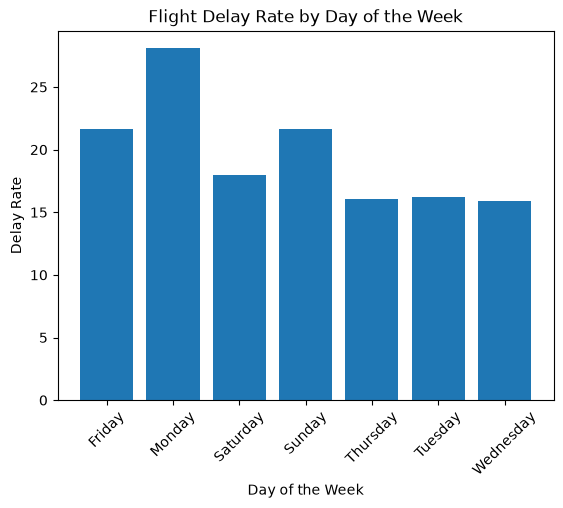

In [17]:
plt.bar(daily_summary.index, daily_summary["delay_rate"])

plt.title("Flight Delay Rate by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Delay Rate")
plt.xticks(rotation=45)
plt.show()

In [21]:
# Extracting departure hour
selected_flights["DEP_HOUR"] = (
    selected_flights["CRS_DEP_TIME"] // 100
)

selected_flights[["CRS_DEP_TIME", "DEP_HOUR"]].head(10)

print(selected_flights[
    ["CRS_DEP_TIME", "DEP_HOUR"]
].head(10))

      CRS_DEP_TIME  DEP_HOUR
1632           644         6
1633           621         6
1634          1120        11
1635          1605        16
1636           732         7
1694          1032        10
1695          2020        20
1696          2057        20
1697          1545        15
1698           805         8


In [22]:
def categorize_time(hour):
    if 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 18:
        return "Afternoon"
    elif 18 <= hour < 24:
        return "Evening"
    else:
        return "Night"

selected_flights["TIME_PERIOD"] = selected_flights["DEP_HOUR"].apply(categorize_time)

selected_flights[["DEP_HOUR", "TIME_PERIOD"]].head(10)

,DEP_HOUR,TIME_PERIOD
1632,6,Morning
1633,6,Morning
1634,11,Morning
1635,16,Afternoon
1636,7,Morning
1694,10,Morning
1695,20,Evening
1696,20,Evening
1697,15,Afternoon
1698,8,Morning


In [23]:
time_summary = selected_flights.groupby("TIME_PERIOD").agg(
    total_flights=("DEP_DEL15", "count"),
    delayed_flights=("DEP_DEL15", "sum")
)

time_summary["delay_rate"] = (
    time_summary["delayed_flights"] /
    time_summary["total_flights"] * 100
)

time_summary

,total_flights,delayed_flights,delay_rate
TIME_PERIOD,,,
Afternoon,7692,1555.0,20.215809
Evening,5543,1280.0,23.092188
Morning,8986,1506.0,16.759404


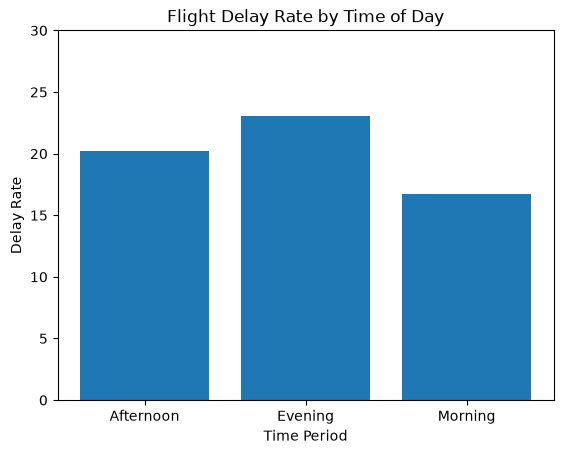

In [25]:
plt.bar(time_summary.index, time_summary["delay_rate"])

plt.title("Flight Delay Rate by Time of Day")
plt.xlabel("Time Period")
plt.ylabel("Delay Rate")
plt.ylim(0, 30)

plt.show()

In [26]:
selected_flights["OP_UNIQUE_CARRIER"].value_counts()

OP_UNIQUE_CARRIER
UA    6736
OO    4479
AA    3788
YX    2951
MQ    2391
DL     763
NK     584
WN     381
F9     226
AS     148
OH     104
B6      53
Name: count, dtype: int64

In [27]:
airline_summary = selected_flights.groupby("OP_UNIQUE_CARRIER").agg(
    total_flights=("DEP_DEL15", "count"),
    delayed_flights=("DEP_DEL15", "sum")
)

airline_summary["delay_rate"] = (
    airline_summary["delayed_flights"] /
    airline_summary["total_flights"] * 100
)

airline_summary.sort_values("delay_rate", ascending=False)

,total_flights,delayed_flights,delay_rate
OP_UNIQUE_CARRIER,,,
AS,148,44.0,29.729730
OO,4384,1176.0,26.824818
F9,218,51.0,23.394495
NK,578,115.0,19.896194
DL,752,149.0,19.813830
UA,6672,1275.0,19.109712
AA,3728,711.0,19.071888
MQ,2354,427.0,18.139337
OH,96,17.0,17.708333


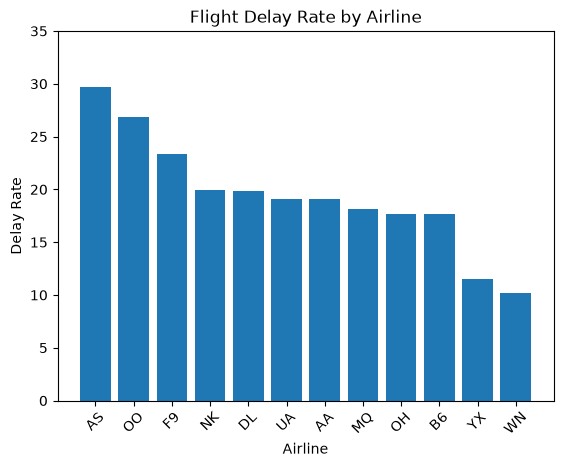

In [28]:
airline_sorted = airline_summary.sort_values(
    "delay_rate", ascending=False
)

plt.bar(airline_sorted.index, airline_sorted["delay_rate"])

plt.title("Flight Delay Rate by Airline")
plt.xlabel("Airline")
plt.ylabel("Delay Rate")
plt.xticks(rotation=45)
plt.ylim(0, 35)

plt.show()

In [29]:
airport_airline_summary = selected_flights.groupby(
    ["ORIGIN", "OP_UNIQUE_CARRIER"]
).agg(
    total_flights=("DEP_DEL15", "count"),
    delayed_flights=("DEP_DEL15", "sum")
)

airport_airline_summary["delay_rate"] = (
    airport_airline_summary["delayed_flights"] /
    airport_airline_summary["total_flights"] * 100
)

airport_airline_summary

total_flights  delayed_flights  delay_rate
ORIGIN OP_UNIQUE_CARRIER                                            
MSN    AA                           157             22.0   14.012739
       DL                           125             12.0    9.600000
       F9                             2              0.0    0.000000
       MQ                            27              2.0    7.407407
       OH                            96             17.0   17.708333
       OO                           288             73.0   25.347222
       UA                            97             10.0   10.309278
       YX                           146             14.0    9.589041
ORD    AA                          3571            689.0   19.294315
       AS                           148             44.0   29.729730
       B6                            51              9.0   17.647059
       DL                           627            137.0   21.850080
       F9                           216             51.0   23.611111
       MQ                          2327            425.0   18.263859
       NK                           578            115.0   19.896194
       OO                          4096           1103.0   26.928711
       UA                          6575           1265.0   19.239544
       WN                           373             38.0   10.187668
       YX                          2721            315.0   11.576626

In [30]:
msn_summary = airport_airline_summary.loc["MSN"]
ord_summary = airport_airline_summary.loc["ORD"]


print(msn_summary)
print(ord_summary)

                   total_flights  delayed_flights  delay_rate
OP_UNIQUE_CARRIER                                            
AA                           157             22.0   14.012739
DL                           125             12.0    9.600000
F9                             2              0.0    0.000000
MQ                            27              2.0    7.407407
OH                            96             17.0   17.708333
OO                           288             73.0   25.347222
UA                            97             10.0   10.309278
YX                           146             14.0    9.589041
                   total_flights  delayed_flights  delay_rate
OP_UNIQUE_CARRIER                                            
AA                          3571            689.0   19.294315
AS                           148             44.0   29.729730
B6                            51              9.0   17.647059
DL                           627            137.0   21.850080
F9      

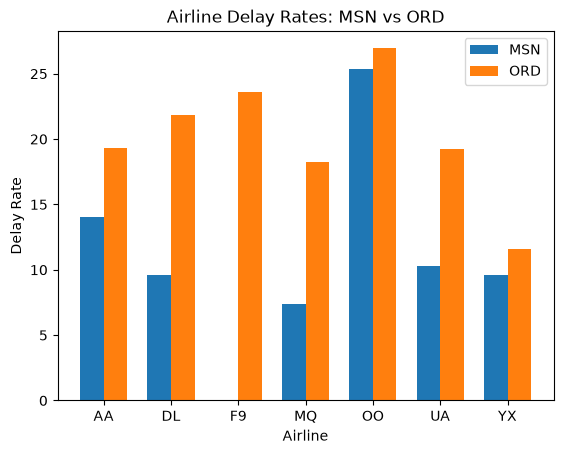

In [31]:
import numpy as np
import matplotlib.pyplot as plt

common_airlines = ["AA", "DL", "F9", "MQ", "OO", "UA", "YX"]

msn_rates = msn_summary.loc[common_airlines, "delay_rate"]
ord_rates = ord_summary.loc[common_airlines, "delay_rate"]

x = np.arange(len(common_airlines))
width = 0.35

plt.bar(x - width/2, msn_rates, width, label="MSN")
plt.bar(x + width/2, ord_rates, width, label="ORD")

plt.title("Airline Delay Rates: MSN vs ORD")
plt.xlabel("Airline")
plt.ylabel("Delay Rate")
plt.xticks(x, common_airlines)
plt.legend()

plt.show()

In [34]:
ord_total = ord["DEP_DEL15"].count()
msn_total = msn["DEP_DEL15"].count()

ord_delayed = (ord["DEP_DEL15"] == 1).sum()
msn_delayed = (msn["DEP_DEL15"] == 1).sum()

print(ord_delayed, ord_total)
print(msn_delayed, msn_total)

4191 21283
150 938


In [35]:
pooled_p = (ord_delayed + msn_delayed) / (ord_total + msn_total)
pooled_p

np.float64(0.19535574456595112)

In [37]:
se = np.sqrt(
    pooled_p * (1 - pooled_p) *
    (1 / ord_total + 1 / msn_total)
)

ord_p = ord_delayed / ord_total
msn_p = msn_delayed / msn_total

z = (ord_p - msn_p) / se
print(se, z)

0.013227537723221399 2.7974227996692735


In [38]:
from scipy.stats import norm

p_value = 2 * (1 - norm.cdf(abs(z)))

p_value

np.float64(0.005151207586602036)

In [39]:
print(ord_p, msn_p, ord_p - msn_p)

0.19691772776394306 0.15991471215351813 0.03700301561042493
